In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

sns.set_theme(style="darkgrid")

cols = ['label',
        'lepton_pT', 'lepton_eta', 'lepton_phi',
        'missing_energy_magnitude', 'missing_energy_phi',
        'jet1pt', 'jet1eta', 'jet1phi', 'jet1b_tag',
        'jet2pt', 'jet2eta', 'jet2phi', 'jet2b_tag',
        'jet3pt', 'jet3eta', 'jet3phi', 'jet3b_tag',
        'jet4pt', 'jet4eta', 'jet4phi', 'jet4b_tag',
        'mjj', 'mjjj', 'mlv', 'mjlv', 'mbb', 'mwbb', 'mwwbb']

df = pd.read_csv('../data/HIGGS.csv', header=None, names=cols, nrows=500000)

# define feature sets
low_level = ['lepton_pT', 'lepton_eta', 'lepton_phi',
             'missing_energy_magnitude', 'missing_energy_phi',
             'jet1pt', 'jet1eta', 'jet1phi', 'jet1b_tag',
             'jet2pt', 'jet2eta', 'jet2phi', 'jet2b_tag',
             'jet3pt', 'jet3eta', 'jet3phi', 'jet3b_tag',
             'jet4pt', 'jet4eta', 'jet4phi', 'jet4b_tag']

high_level  = ['mjj', 'mjjj', 'mlv', 'mjlv', 'mbb', 'mwbb', 'mwwbb']
all_features = low_level + high_level

y = df['label']

feature_sets = {
    'Low-level (21)':  low_level,
    'High-level (7)':  high_level,
    'All features (28)': all_features
}

print("Feature sets defined:")
for name, feats in feature_sets.items():
    print(f"  {name}: {len(feats)} features")
print("✅")

Feature sets defined:
  Low-level (21): 21 features
  High-level (7): 7 features
  All features (28): 28 features
✅


In [3]:
xgb_results = {}

for name, features in feature_sets.items():
    print(f"\nTraining XGBoost on {name}...")
    
    X = df[features]
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    
    model = xgb.XGBClassifier(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='auc',
        random_state=42,
        n_jobs=-1
    )
    
    model.fit(X_train, y_train, verbose=False)
    
    y_prob = model.predict_proba(X_test)[:, 1]
    auc    = roc_auc_score(y_test, y_prob)
    
    xgb_results[name] = auc
    print(f"  AUC: {auc:.4f}")

print("\nXGBoost experiment done ✅")


Training XGBoost on Low-level (21)...
  AUC: 0.7199

Training XGBoost on High-level (7)...
  AUC: 0.7864

Training XGBoost on All features (28)...
  AUC: 0.8185

XGBoost experiment done ✅


In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def build_model(input_size):
    """builds a network scaled to input size"""
    return nn.Sequential(
        nn.Linear(input_size, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(256, 256),        nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(256, 128),        nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.1),
        nn.Linear(128, 64),         nn.BatchNorm1d(64),  nn.ReLU(),
        nn.Linear(64, 1),           nn.Sigmoid()
    ).to(device)

def train_nn(X_train, y_train, X_test, y_test, epochs=25):
    """trains a neural network and returns test AUC"""
    
    scaler    = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s  = scaler.transform(X_test)
    
    X_train_t = torch.FloatTensor(X_train_s).to(device)
    y_train_t = torch.FloatTensor(y_train.values.copy()).to(device)
    X_test_t  = torch.FloatTensor(X_test_s).to(device)
    
    loader = DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=1024, shuffle=True
    )
    
    model     = build_model(X_train.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)
    criterion = nn.BCELoss()
    
    for epoch in range(epochs):
        model.train()
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = criterion(model(X_batch).squeeze(), y_batch)
            loss.backward()
            optimizer.step()
        
        if (epoch+1) % 5 == 0:
            model.eval()
            with torch.no_grad():
                y_prob = model(X_test_t).squeeze().cpu().numpy()
            auc = roc_auc_score(y_test, y_prob)
            print(f"    Epoch {epoch+1}/{epochs} | AUC: {auc:.4f}")
    
    model.eval()
    with torch.no_grad():
        y_prob = model(X_test_t).squeeze().cpu().numpy()
    
    return roc_auc_score(y_test, y_prob)

In [5]:
nn_results = {}

for name, features in feature_sets.items():
    print(f"\nTraining Neural Network on {name}...")
    
    X = df[features]
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    
    auc = train_nn(X_train, y_train, X_test, y_test, epochs=25)
    nn_results[name] = auc
    print(f"  Final AUC: {auc:.4f}")

print("\nNeural Network experiment done ✅")


Training Neural Network on Low-level (21)...
    Epoch 5/25 | AUC: 0.7359
    Epoch 10/25 | AUC: 0.7510
    Epoch 15/25 | AUC: 0.7588
    Epoch 20/25 | AUC: 0.7618
    Epoch 25/25 | AUC: 0.7649
  Final AUC: 0.7649

Training Neural Network on High-level (7)...
    Epoch 5/25 | AUC: 0.7857
    Epoch 10/25 | AUC: 0.7880
    Epoch 15/25 | AUC: 0.7900
    Epoch 20/25 | AUC: 0.7904
    Epoch 25/25 | AUC: 0.7916
  Final AUC: 0.7916

Training Neural Network on All features (28)...
    Epoch 5/25 | AUC: 0.8124
    Epoch 10/25 | AUC: 0.8243
    Epoch 15/25 | AUC: 0.8306
    Epoch 20/25 | AUC: 0.8332
    Epoch 25/25 | AUC: 0.8349
  Final AUC: 0.8349

Neural Network experiment done ✅


In [6]:
results_df = pd.DataFrame({
    'Feature Set':    list(feature_sets.keys()),
    'XGBoost AUC':   [xgb_results[k] for k in feature_sets.keys()],
    'Neural Net AUC': [nn_results[k]  for k in feature_sets.keys()]
})

results_df['NN advantage'] = (
    results_df['Neural Net AUC'] - results_df['XGBoost AUC']
).round(4)

results_df = results_df.round(4)
print(results_df.to_string(index=False))
results_df.to_csv('../models/feature_experiment_results.csv', index=False)
print("\nSaved ✅")

      Feature Set  XGBoost AUC  Neural Net AUC  NN advantage
   Low-level (21)       0.7199          0.7649        0.0449
   High-level (7)       0.7864          0.7916        0.0051
All features (28)       0.8185          0.8349        0.0164

Saved ✅


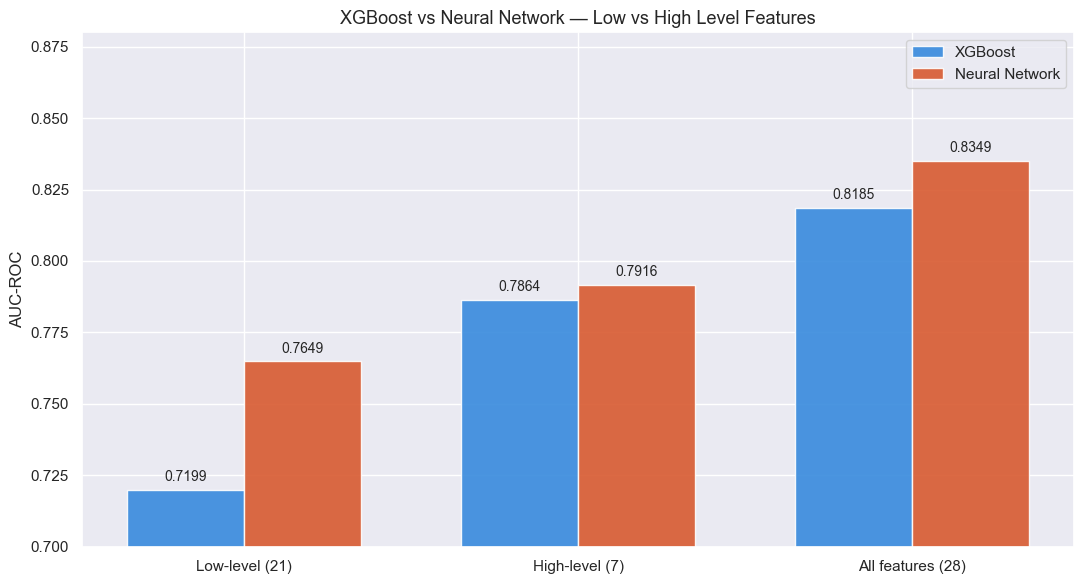

In [7]:
x     = np.arange(len(feature_sets))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(x - width/2, 
               [xgb_results[k] for k in feature_sets.keys()],
               width, label='XGBoost', color='#378ADD', alpha=0.9)

bars2 = ax.bar(x + width/2,
               [nn_results[k] for k in feature_sets.keys()],
               width, label='Neural Network', color='#D85A30', alpha=0.9)

# add value labels on bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.002,
            f'{bar.get_height():.4f}',
            ha='center', va='bottom', fontsize=10)

for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.002,
            f'{bar.get_height():.4f}',
            ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(list(feature_sets.keys()), fontsize=11)
ax.set_ylim(0.70, 0.88)
ax.set_ylabel('AUC-ROC', fontsize=12)
ax.set_title('XGBoost vs Neural Network — Low vs High Level Features', fontsize=13)
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig('../plots/feature_experiment.png', dpi=150)
plt.show()

## Feature Experiment — Observations

Fill in after running. Key things to look for:

1. Does high-level alone beat low-level alone?
   → Expected yes — physicist knowledge is powerful

2. Is the NN advantage larger on low-level features?
   → Expected yes — NN can learn implicit physics relationships
   → This is the core finding of Baldi et al. (2014)

3. Does combining all features beat either alone?
   → Expected yes — more information = better classification

4. How close does low-level NN get to high-level XGBoost?
   → This measures how much the NN compensates for missing domain knowledge